In [2]:
from collections import Counter
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import hashlib
from pathlib import Path
# Dynamic multi-directional project root resolver
here = Path.cwd().resolve()
ROOT = None
for candidate in [here, *here.parents, here / "SIH2026-main"]:
    if candidate.is_dir() and (candidate / "dataset").is_dir() and (candidate / "ml").is_dir():
        ROOT = candidate.resolve()
        break
if ROOT is None:
    for d in here.glob("**/ml"):
        if (d.parent / "dataset").is_dir():
            ROOT = d.parent.resolve()
            break
assert ROOT is not None, "Project root not found (must contain 'dataset' and 'ml')"

# Dataset path
dataset = ROOT / "dataset" / "Ml_project_dataset"
image_dir = dataset / "images"
mask_dir = dataset / "masks"

print("Project root:", ROOT)
print("Dataset found:", dataset.exists())
print("Images folder:", image_dir.exists())
print("Masks folder:", mask_dir.exists())


Project root: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main
Dataset found: True
Images folder: True
Masks folder: True


In [3]:

image_files = sorted(image_dir.rglob("*.png"))
mask_files = sorted(mask_dir.rglob("*.png"))

print("Total images:", len(image_files))
print("Total masks:", len(mask_files))

image_splits = Counter(p.parent.name for p in image_files)
mask_splits = Counter(p.parent.name for p in mask_files)

print("\nImage splits:", dict(image_splits))
print("Mask splits:", dict(mask_splits))


Total images: 8070
Total masks: 8070

Image splits: {'train': 6455, 'val': 1615}
Mask splits: {'train': 6455, 'val': 1615}


In [4]:

image_map = {}
mask_map = {}

for p in image_files:
    key = (p.parent.name, p.stem)
    image_map[key] = p

for p in mask_files:
    key = (p.parent.name, p.stem)
    mask_map[key] = p

valid_keys = sorted(set(image_map) & set(mask_map))

print("Matched pairs:", len(valid_keys))
print("Missing masks:", len(set(image_map) - set(mask_map)))
print("Missing images:", len(set(mask_map) - set(image_map)))


Matched pairs: 8070
Missing masks: 0
Missing images: 0


In [5]:

rows = []

for key in valid_keys:
    ip = image_map[key]
    mp = mask_map[key]

    try:
        with Image.open(ip) as img, Image.open(mp) as mask:
            img.load()
            mask.load()

            rows.append({
                "split": key[0],
                "image": ip.name,
                "image_mode": img.mode,
                "mask_mode": mask.mode,
                "image_size": str(img.size),
                "mask_size": str(mask.size),
                "size_match": img.size == mask.size,
                "error": ""
            })

    except Exception as e:
        rows.append({
            "split": key[0],
            "image": ip.name,
            "size_match": False,
            "error": str(e)
        })

df = pd.DataFrame(rows)

print("Checked pairs:", len(df))
print("Size mismatches:", (df["size_match"] == False).sum())
print("Unreadable pairs:", (df["error"] != "").sum())

print("\nImage modes:")
print(df["image_mode"].value_counts())

print("\nMask modes:")
print(df["mask_mode"].value_counts())

print("\nImage sizes:")
print(df["image_size"].value_counts().head(10))


Checked pairs: 8070
Size mismatches: 0
Unreadable pairs: 0

Image modes:
image_mode
RGB    8070
Name: count, dtype: int64

Mask modes:
mask_mode
RGB    4800
L      3270
Name: count, dtype: int64

Image sizes:
image_size
(256, 256)    8070
Name: count, dtype: int64


In [6]:

hashes = []

for p in image_files:
    with open(p, "rb") as f:
        code = hashlib.sha256(f.read()).hexdigest()

    hashes.append({
        "file": str(p),
        "split": p.parent.name,
        "hash": code
    })

hash_df = pd.DataFrame(hashes)

duplicates = hash_df[
    hash_df.duplicated("hash", keep=False)
]

print("Files with identical content:", len(duplicates))

cross_split = duplicates.groupby("hash").filter(
    lambda group: group["split"].nunique() > 1
)

print("Duplicate files across splits:", len(cross_split))

display(duplicates.head(10))


Files with identical content: 0
Duplicate files across splits: 0


,file,split,hash


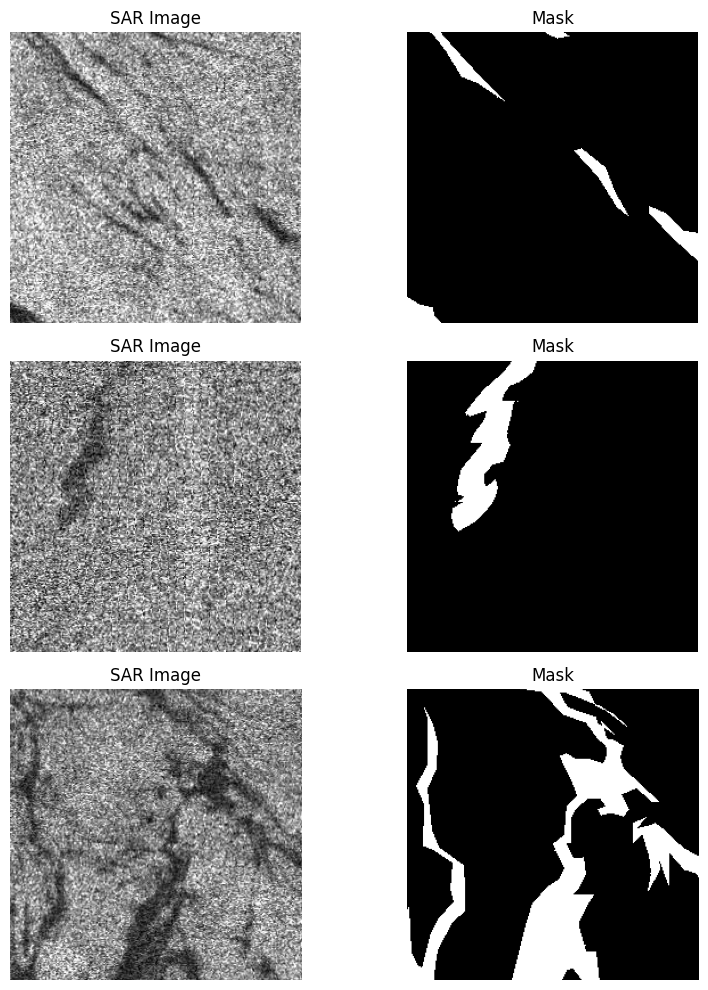

In [7]:

fig, axes = plt.subplots(3, 2, figsize=(9, 10))

for i, key in enumerate(valid_keys[:3]):
    with Image.open(image_map[key]) as img:
        axes[i, 0].imshow(img)

    with Image.open(mask_map[key]) as mask:
        axes[i, 1].imshow(mask, cmap="gray")

    axes[i, 0].set_title("SAR Image")
    axes[i, 1].set_title("Mask")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

report_dir = dataset.parent / "audit_reports"
report_dir.mkdir(exist_ok=True)

df.to_csv(report_dir / "dataset_inspection.csv", index=False)
duplicates.to_csv(report_dir / "duplicate_images.csv", index=False)

print("DATASET INSPECTION SUMMARY")
print("Total images:", len(image_files))
print("Total masks:", len(mask_files))
print("Matched pairs:", len(valid_keys))
print("Size mismatches:", (df["size_match"] == False).sum())
print("Exact duplicate files:", len(duplicates))
print("Report saved in:", report_dir)


DATASET INSPECTION SUMMARY
Total images: 8070
Total masks: 8070
Matched pairs: 8070
Size mismatches: 0
Exact duplicate files: 0
Report saved in: C:\Users\navjo\OneDrive\Desktop\SIH2026-main\SIH2026-main\dataset\audit_reports


: 